# RL2, MAML and VariBAD-Style Meta-RL

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Separate synthetic plotting demonstrations (source cells 51 and 52) from real training outputs. The five-seed actual first-rollout → adapted mean returns are VariBAD −218.996 → −219.368, MAML −244.290 → −244.680, RL2 −270.850 → −271.555; these show no positive mean adaptation gain. One-million-frame settings and sparse evaluation are not the full paper budget or a faithful paper reproduction. VariBAD-style is an educational variant.


# Reproducing Meta-RL Learning Curves on HalfCheetahVel

## VariBAD, MAML, and RL2

> **You may change, replace, split, merge, reorder, or delete any cell in this notebook.**
>
> The provided structure is only a starting point. Your implementation may use different classes,
> helper functions, optimizers, data structures, or training loops, provided that you satisfy the
> experimental protocol and clearly document every departure from the papers.

Your goal is to implement three meta-reinforcement-learning algorithms in **PyTorch**, using the
papers as the primary specifications:

1. **VariBAD**
2. **MAML for reinforcement learning**
3. **RL2**

You will then reproduce the result in **Figures 4 and 6** of the VariBAD paper for the **HalfCheetahVel** task.

## Required papers

Read the papers before implementing the methods.

### VariBAD

**Zintgraf et al., "VariBAD: A Very Good Method for Bayes-Adaptive Deep RL via Meta-Learning," ICLR 2020**

- Paper: https://arxiv.org/abs/1910.08348

### RL2

**Duan et al., "RL2: Fast Reinforcement Learning via Slow Reinforcement Learning," 2016**

- Paper: https://arxiv.org/abs/1611.02779

### MAML

**Finn, Abbeel, and Levine, "Model-Agnostic Meta-Learning for Fast Adaptation of Deep Networks," ICML 2017**

- Paper: https://arxiv.org/abs/1703.03400

### Important difference

The published VariBAD Figure 6 compares against **E-MAML**, not plain MAML. This assignment asks
you to implement **vanilla MAML** from the MAML paper.

### Figure 4 reproduction note

The published Figure 4 reports **average meta-test return over the first five rollouts** for each
MuJoCo environment. In this notebook, reproduce only the **HalfCheetahVel** panel and compare the
three required implementations: VariBAD, RL2, and vanilla MAML.

As with Figure 6, this is not an exact method-for-method reproduction of the published panel because
the paper reports **E-MAML**, while this assignment requires **vanilla MAML**. Clearly label the
result as a Figure 4-style HalfCheetahVel reproduction.


## Learning objectives

By completing this assignment, you should be able to:

- distinguish optimization-based, recurrent, and inference-based meta-RL;
- implement a hidden-task continuous-control benchmark;
- separate meta-training tasks from held-out meta-test tasks;
- implement within-task adaptation without leaking the task identity.

## HalfCheetahVel protocol

Each task is defined by a hidden target velocity $v^\star$. The agent observes the standard
HalfCheetah state but **does not observe $v^\star$**.

At each time step, use

$$
r_t = -\left|v_t-v^\star\right| - 0.05\lVert a_t\rVert_2^2,
$$

where $v_t$ is the forward velocity and $a_t$ is the action.

### Required benchmark settings

- Target velocities are sampled from $[0,3]$.
- One MDP episode has horizon $H=200$.
- VariBAD and RL2 are trained on two consecutive episodes of the same task:
  $$
  H^+ = 2H = 400.
  $$
- The physical environment resets after the first episode, but:
  - RL2 must preserve its recurrent hidden state;
  - VariBAD must preserve its inferred task posterior;
  - a done/reset indicator must be made available to recurrent inference.
- MAML adapts through gradient updates computed from support trajectories and is evaluated on a
  fresh query trajectory.
- Meta-test tasks must not be used for gradient updates during meta-training.
- The target velocity or task ID must never be passed directly to the policy, encoder, critic, or
  value function.

## What must be submitted

1. This completed notebook.
2. Implementations of VariBAD, MAML, and RL2.
3. Training curves.

You may checkpoint models during training, but the final plots must be generated by code in this
notebook.

### Required figure outputs

The completed notebook must generate both of the following for **HalfCheetahVel only**:

1. A **Figure 6-style** two-panel learning-curve plot versus meta-training environment frames,
   showing first-rollout and adapted/method-specific final-rollout return.
2. A **Figure 4-style** plot showing average test return for rollouts 1 through 5 at the selected
   final checkpoint.

Both figures must be generated from the actual trained models, not from manually entered values.


In [237]:
# Colab setup.
# Run this cell once in a fresh runtime, then restart the runtime only if Colab requests it.

%pip install -q "gymnasium[mujoco]>=1.0,<2" "mujoco>=3.2,<4" \
    "numpy>=1.24" "pandas>=2.0" "matplotlib>=3.7" "tqdm>=4.66"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [238]:
import math
import os
import random
import time
from collections import OrderedDict
from dataclasses import asdict, dataclass
from typing import Any, Dict, List, Mapping, Optional, Sequence, Tuple

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Normal, kl_divergence
from tqdm.auto import tqdm

try:
    from torch.func import functional_call
except ImportError:  # PyTorch < 2.0 fallback
    from torch.nn.utils.stateless import functional_call

In [239]:
@dataclass
class ExperimentConfig:
    # Environment and task distribution
    env_id: str = "HalfCheetah-v5"
    velocity_low: float = 0.0
    velocity_high: float = 3.0
    episode_horizon: int = 200
    recurrent_rollouts_per_task: int = 2

    # Task splits
    num_train_tasks: int = 100
    num_validation_tasks: int = 20
    num_test_tasks: int = 30
    task_split_seed: int = 2026

    # Full reproduction target
    total_frames: int = 1_000_000
    # 1000000
    evaluation_interval_frames: int = 1_000_000
    evaluation_tasks: int = 30
    evaluation_episodes_per_task: int = 1
    seeds: Tuple[int, ...] = (11, 22, 33, 44, 55)

    # Shared RL defaults. Each method may override these.
    gamma: float = 0.97
    gae_lambda: float = 0.90
    max_grad_norm: float = 0.5

    # Logging
    verbose_interval_updates: int = 10


FULL_CONFIG = ExperimentConfig(total_frames=1000000)

# A small configuration for debugging interfaces only.
DEBUG_CONFIG = ExperimentConfig(
    num_train_tasks=8,
    num_validation_tasks=4,
    num_test_tasks=4,
    total_frames=20_000,
    evaluation_interval_frames=5_000,
    evaluation_tasks=4,
    seeds=(0,),
)

# Change this during development.
# CONFIG = DEBUG_CONFIG
CONFIG = FULL_CONFIG

print(asdict(CONFIG))

{'env_id': 'HalfCheetah-v5', 'velocity_low': 0.0, 'velocity_high': 3.0, 'episode_horizon': 200, 'recurrent_rollouts_per_task': 2, 'num_train_tasks': 100, 'num_validation_tasks': 20, 'num_test_tasks': 30, 'task_split_seed': 2026, 'total_frames': 1000000, 'evaluation_interval_frames': 1000000, 'evaluation_tasks': 30, 'evaluation_episodes_per_task': 1, 'seeds': (11, 22, 33, 44, 55), 'gamma': 0.97, 'gae_lambda': 0.9, 'max_grad_norm': 0.5, 'verbose_interval_updates': 10}


In [240]:
# Figure 4 evaluates five consecutive meta-test rollouts at the selected checkpoint.
# This is kept separate from the existing configuration fields so the original
# experiment configuration remains unchanged.
FIGURE4_EVALUATION_ROLLOUTS: int = 5


In [241]:
def seed_everything(seed: int) -> None:
    """Seed Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Provided environment infrastructure

The following wrapper defines the common benchmark. You may modify its implementation, but all
methods must ultimately be evaluated with the same reward, task split, horizon, and observation
semantics.

The standard Gymnasium HalfCheetah observation does not expose the global torso $x$-position.
The wrapper recomputes the reward using the hidden target velocity.

In [242]:
class HalfCheetahVel(gym.Wrapper):
    """HalfCheetah with a hidden target-velocity task."""

    def __init__(
        self,
        target_velocity: float,
        env_id: str = "HalfCheetah-v5",
        horizon: int = 200,
        render_mode: Optional[str] = None,
    ):
        base_env = gym.make(
            env_id,
            render_mode=render_mode,
            max_episode_steps=horizon,
        )
        super().__init__(base_env)
        self.target_velocity = float(target_velocity)
        self.horizon = int(horizon)
        self._elapsed_steps_local = 0

    @property
    def task(self) -> Dict[str, float]:
        # This property is for experiment control and logging only.
        # Do not feed it to an agent.
        return {"velocity": self.target_velocity}

    def reset(
        self,
        *,
        seed: Optional[int] = None,
        options: Optional[dict] = None,
    ):
        self._elapsed_steps_local = 0
        obs, info = self.env.reset(seed=seed, options=options)
        info = dict(info)
        info["task_velocity_for_logging_only"] = self.target_velocity
        return obs.astype(np.float32), info

    def step(self, action):
        x_before = float(self.unwrapped.data.qpos[0])
        _, _, terminated, truncated, info = self.env.step(action)
        x_after = float(self.unwrapped.data.qpos[0])

        forward_velocity = (x_after - x_before) / float(self.unwrapped.dt)
        velocity_reward = -abs(forward_velocity - self.target_velocity)
        control_cost = 0.05 * float(np.square(action).sum())
        reward = velocity_reward - control_cost

        self._elapsed_steps_local += 1
        obs = self.unwrapped._get_obs().astype(np.float32)

        info = dict(info)
        info.update(
            {
                "forward_velocity": forward_velocity,
                "velocity_error": forward_velocity - self.target_velocity,
                "reward_velocity": velocity_reward,
                "reward_control": -control_cost,
                "task_velocity_for_logging_only": self.target_velocity,
            }
        )
        return obs, float(reward), bool(terminated), bool(truncated), info

In [243]:
@dataclass(frozen=True)
class TaskSplits:
    train: np.ndarray
    validation: np.ndarray
    test: np.ndarray


def make_task_splits(config: ExperimentConfig) -> TaskSplits:
    """Create deterministic, disjoint finite task sets."""
    rng = np.random.default_rng(config.task_split_seed)
    total = config.num_train_tasks + config.num_validation_tasks + config.num_test_tasks
    velocities = rng.uniform(
        config.velocity_low,
        config.velocity_high,
        size=total,
    ).astype(np.float32)

    n_train = config.num_train_tasks
    n_val = config.num_validation_tasks

    return TaskSplits(
        train=velocities[:n_train],
        validation=velocities[n_train:n_train + n_val],
        test=velocities[n_train + n_val:],
    )


TASKS = make_task_splits(CONFIG)
print("Training tasks:", TASKS.train)
print("Validation tasks:", TASKS.validation)
print("Test tasks:", TASKS.test)

Training tasks: [0.53680444 1.9197395  1.4018052  1.1115016  1.064752   2.3715549
 2.7154315  0.53205955 1.9583544  0.8949083  2.9008865  2.7595506
 1.9076124  2.2581964  1.545461   2.4776857  1.3451416  1.0164374
 0.8336976  0.6789992  1.5774505  1.2927362  1.9895419  0.03852145
 1.3431057  1.0955424  0.5861928  1.7845976  1.3059394  0.8999745
 0.62824833 2.6238723  2.392387   1.820129   1.0353017  2.8404593
 1.6901321  1.2982882  2.7013488  0.9580254  2.0879846  0.94146097
 0.78465915 2.1025226  0.68367594 1.479331   1.7400854  0.5667191
 2.193722   1.6454492  1.8645098  1.1164329  1.2605798  1.4844891
 1.4099127  2.0269177  1.7315325  1.248812   0.00540706 2.3820932
 1.5581527  0.979634   1.499865   0.2803378  2.7141123  2.9692085
 0.17620565 1.0746937  2.1901937  0.9427144  1.7011492  1.249713
 2.3226364  2.8753932  2.6651862  1.8628064  0.48082295 2.8411863
 0.07089729 0.8931284  0.84484047 2.015478   1.4620892  0.27866563
 0.03857366 1.8129473  1.47445    1.8041464  1.6920716  2.

In [244]:
# Environment smoke test

seed_everything(0)
test_env = HalfCheetahVel(
    target_velocity=float(TASKS.train[0]),
    env_id=CONFIG.env_id,
    horizon=CONFIG.episode_horizon,
)
obs, info = test_env.reset(seed=0)
action = test_env.action_space.sample()
next_obs, reward, terminated, truncated, info = test_env.step(action)

print("Observation shape:", obs.shape)
print("Action shape:", action.shape)
print("One-step reward:", reward)
print("Forward velocity:", info["forward_velocity"])
print("Target velocity:", info["task_velocity_for_logging_only"])

assert obs.ndim == 1
assert next_obs.shape == obs.shape
assert np.isfinite(reward)
test_env.close()

Observation shape: (17,)
Action shape: (6,)
One-step reward: -0.17525023520591745
Forward velocity: 0.4368305534064483
Target velocity: 0.5368044376373291


## Common result contract

You may organize training however you want, but each completed run must be converted to the
following in-memory format so that the provided plotting tools can compare methods.

```python
history = {
    "method": "VariBAD",               # or "RL2", "MAML"
    "seed": 11,
    "frames": np.ndarray,              # shape [K], monotonically increasing
    "first_rollout_return": np.ndarray,# shape [K]
    "adapted_return": np.ndarray,      # shape [K]
    "metadata": {...},                 # hyperparameters and protocol
}
```

Interpretation:

- `first_rollout_return`: mean return on the first episode of held-out tasks, before useful
  task-specific information is available.
- `adapted_return`:
  - VariBAD: second rollout while retaining the posterior;
  - RL2: second rollout while retaining the recurrent state;
  - MAML: query rollout after the declared support-set gradient adaptation.

All evaluation must use the same fixed held-out task set for a given seed and checkpoint.

### Figure 4 result contract

The Figure 4-style evaluation requires per-seed, per-task, per-rollout returns at the selected final
checkpoint. Store them as:

```python
figure4_rollout_results = {
    "VariBAD": np.ndarray,  # [num_seeds, num_test_tasks, 5]
    "RL2": np.ndarray,      # [num_seeds, num_test_tasks, 5]
    "MAML": np.ndarray,     # [num_seeds, num_test_tasks, 5]
}
```

For VariBAD and RL2, do not reset adaptation state between the five rollouts of a task. For MAML,
retain only the task-specific fast parameters between rollouts and reset them to the learned
meta-initialization when moving to a new task. Preserve the individual task dimension until after all
evaluation data have been collected.


In [245]:
def validate_history(history: Mapping[str, Any]) -> None:
    """Validate the output format expected by the plotting utilities."""
    required = {
        "method",
        "seed",
        "frames",
        "first_rollout_return",
        "adapted_return",
        "metadata",
    }
    missing = required.difference(history.keys())
    if missing:
        raise KeyError(f"History is missing keys: {sorted(missing)}")

    frames = np.asarray(history["frames"], dtype=np.float64)
    first = np.asarray(history["first_rollout_return"], dtype=np.float64)
    adapted = np.asarray(history["adapted_return"], dtype=np.float64)

    if not (frames.ndim == first.ndim == adapted.ndim == 1):
        raise ValueError("frames and return arrays must all be one-dimensional.")
    if not (len(frames) == len(first) == len(adapted)):
        raise ValueError("frames and return arrays must have equal lengths.")
    if len(frames) == 0:
        raise ValueError("history may not be empty.")
    if np.any(np.diff(frames) <= 0):
        raise ValueError("frames must be strictly increasing.")
    if not np.all(np.isfinite(first)) or not np.all(np.isfinite(adapted)):
        raise ValueError("Return arrays contain non-finite values.")

# Part I - Shared reinforcement-learning infrastructure

You will probably need:

- a diagonal Gaussian policy for continuous actions;
- correct action scaling or clipping;
- log-probabilities under the behavior policy;
- a value function;
- trajectory storage;
- return and advantage computation;
- generalized advantage estimation;
- an on-policy optimizer such as PPO or TRPO;
- checkpoint and evaluation utilities;
- careful treatment of time-limit truncation.

These helpers may be shared across methods. Do not accidentally detach tensors needed by MAML's
meta-gradient, and do not shuffle recurrent sequences in a way that destroys temporal order.

In [246]:
@dataclass
class TrajectoryBatch:
    """A time-major on-policy trajectory; leading dimension T is time."""

    observations: torch.Tensor          # [T, observation_dim]
    actions: torch.Tensor               # [T, action_dim]
    rewards: torch.Tensor               # [T]
    next_observations: torch.Tensor     # [T, observation_dim]
    terminated: torch.Tensor            # [T], true MDP terminations
    truncated: torch.Tensor             # [T], time-limit endings
    dones_for_agent: torch.Tensor       # [T], recurrent/GAE boundary mask
    log_probs: Optional[torch.Tensor] = None
    values: Optional[torch.Tensor] = None
    returns: Optional[torch.Tensor] = None
    advantages: Optional[torch.Tensor] = None
    policy_inputs: Optional[torch.Tensor] = None
    latent_beliefs: Optional[torch.Tensor] = None


class SquashedNormal:
    """Diagonal Gaussian followed by tanh, with a stable change of variables."""

    def __init__(self, mean: torch.Tensor, log_std: torch.Tensor):
        self.mean = mean
        self.log_std = log_std.clamp(-5.0, 2.0).expand_as(mean)
        self.base = Normal(mean, self.log_std.exp())

    @property
    def mode(self) -> torch.Tensor:
        return torch.tanh(self.mean)

    def rsample(self) -> torch.Tensor:
        return torch.tanh(self.base.rsample())

    def sample(self) -> torch.Tensor:
        return torch.tanh(self.base.sample())

    def log_prob(self, action: torch.Tensor) -> torch.Tensor:
        action = action.clamp(-1.0 + 1e-6, 1.0 - 1e-6)
        pre_tanh = torch.atanh(action)
        correction = torch.log(1.0 - action.square() + 1e-6)
        return (self.base.log_prob(pre_tanh) - correction).sum(dim=-1)

    def entropy(self) -> torch.Tensor:
        # Entropy of the unsquashed Gaussian is a stable PPO exploration proxy.
        return self.base.entropy().sum(dim=-1)


def make_mlp(
    input_dim: int,
    hidden_sizes: Sequence[int],
    output_dim: int,
    activation: type[nn.Module] = nn.Tanh,
) -> nn.Sequential:
    layers: List[nn.Module] = []
    previous = input_dim
    for width in hidden_sizes:
        layers.extend((nn.Linear(previous, int(width)), activation()))
        previous = int(width)
    layers.append(nn.Linear(previous, output_dim))
    return nn.Sequential(*layers)


def concatenate_batches(batches: Sequence[TrajectoryBatch]) -> TrajectoryBatch:
    """Concatenate feedforward episodes without changing within-episode order."""
    if not batches:
        raise ValueError("At least one trajectory is required.")

    def cat(name: str) -> Optional[torch.Tensor]:
        values = [getattr(batch, name) for batch in batches]
        return None if values[0] is None else torch.cat(values, dim=0)

    return TrajectoryBatch(**{
        field: cat(field)
        for field in TrajectoryBatch.__dataclass_fields__
    })


def compute_returns_and_advantages(
    rewards: torch.Tensor,
    values: torch.Tensor,
    terminated: torch.Tensor,
    truncated: torch.Tensor,
    gamma: float,
    gae_lambda: float,
    bootstrap_value: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Compute time-major GAE for tensors shaped [T] or [T, B].

    A true termination suppresses value bootstrapping. A time-limit truncation
    retains the final bootstrap value, but stops the GAE recursion so estimates
    do not leak into a separately reset episode.
    """
    if not (rewards.shape == values.shape == terminated.shape == truncated.shape):
        raise ValueError("rewards, values, terminated, and truncated must share a shape.")
    if rewards.ndim not in (1, 2):
        raise ValueError("Expected [T] or [T, B] tensors.")

    dtype = values.dtype
    terminated_f = terminated.to(dtype)
    episode_done = torch.logical_or(terminated.bool(), truncated.bool()).to(dtype)
    advantages = torch.zeros_like(rewards)
    gae = torch.zeros_like(bootstrap_value, dtype=dtype, device=values.device)

    for t in reversed(range(rewards.shape[0])):
        next_value = bootstrap_value if t == rewards.shape[0] - 1 else values[t + 1]
        delta = rewards[t] + gamma * (1.0 - terminated_f[t]) * next_value - values[t]
        gae = delta + gamma * gae_lambda * (1.0 - episode_done[t]) * gae
        advantages[t] = gae

    return advantages + values, advantages


def normalized(tensor: torch.Tensor) -> torch.Tensor:
    return (tensor - tensor.mean()) / (tensor.std(unbiased=False) + 1e-8)

In [247]:
def collect_episode(
    env: gym.Env,
    agent: Any,
    *,
    deterministic: bool,
    device: torch.device,
    agent_state: Optional[Any] = None,
) -> Tuple[TrajectoryBatch, Any, float]:
    """Collect one feedforward episode using ``agent.rollout_step``.

    ``agent_state`` can hold MAML fast parameters. Recurrent methods use their
    own trial collectors because their state must cross physical episode resets.
    """
    observation, _ = env.reset()
    state = agent_state
    observations, actions, rewards, next_observations = [], [], [], []
    terminated_flags, truncated_flags, log_probs, values = [], [], [], []
    episode_return = 0.0

    while True:
        action, log_prob, value, state = agent.rollout_step(
            observation, state, deterministic=deterministic
        )
        next_observation, reward, terminated, truncated, _ = env.step(action)

        observations.append(observation)
        actions.append(action)
        rewards.append(reward)
        next_observations.append(next_observation)
        terminated_flags.append(terminated)
        truncated_flags.append(truncated)
        log_probs.append(log_prob)
        values.append(value)
        episode_return += float(reward)
        observation = next_observation

        if terminated or truncated:
            break

    obs_tensor = torch.as_tensor(np.asarray(observations), dtype=torch.float32, device=device)
    action_tensor = torch.as_tensor(np.asarray(actions), dtype=torch.float32, device=device)
    reward_tensor = torch.as_tensor(rewards, dtype=torch.float32, device=device)
    next_obs_tensor = torch.as_tensor(
        np.asarray(next_observations), dtype=torch.float32, device=device
    )
    terminated_tensor = torch.as_tensor(terminated_flags, dtype=torch.bool, device=device)
    truncated_tensor = torch.as_tensor(truncated_flags, dtype=torch.bool, device=device)
    value_tensor = torch.as_tensor(values, dtype=torch.float32, device=device)

    with torch.no_grad():
        bootstrap = (
            torch.zeros((), device=device)
            if bool(terminated_tensor[-1])
            else agent.bootstrap_value(next_observations[-1], state)
        )
    returns, advantages = compute_returns_and_advantages(
        reward_tensor,
        value_tensor,
        terminated_tensor,
        truncated_tensor,
        agent.gamma,
        agent.gae_lambda,
        bootstrap,
    )

    batch = TrajectoryBatch(
        observations=obs_tensor,
        actions=action_tensor,
        rewards=reward_tensor,
        next_observations=next_obs_tensor,
        terminated=terminated_tensor,
        truncated=truncated_tensor,
        dones_for_agent=torch.logical_or(terminated_tensor, truncated_tensor),
        log_probs=torch.as_tensor(log_probs, dtype=torch.float32, device=device),
        values=value_tensor,
        returns=returns,
        advantages=advantages,
    )
    return batch, state, episode_return

# Part II - MAML

## Algorithm summary

MAML learns an initialization $\theta$ such that a small policy-gradient update produces a policy
that performs well on a new task.

For a sampled task $\mathcal T_i$:

1. Collect support trajectories using $\pi_\theta$.
2. Compute a task loss $\mathcal L_{\mathcal T_i}^{\text{support}}(\theta)$.
3. Perform one or more differentiable inner updates:
   $$
   \theta_i' = \theta - \alpha \nabla_\theta
   \mathcal L_{\mathcal T_i}^{\text{support}}(\theta).
   $$
4. Collect fresh query trajectories using $\pi_{\theta_i'}$.
5. Update the shared initialization using query losses:
   $$
   \theta \leftarrow \theta - \beta \nabla_\theta
   \sum_i \mathcal L_{\mathcal T_i}^{\text{query}}(\theta_i').
   $$

In [248]:
# MAML uses functional_call to evaluate the policy under differentiable fast
# parameters. OrderedDict preserves the policy's named-parameter order.

In [249]:
class MAMLPolicy(nn.Module):
    """Tanh-squashed stochastic policy supporting functional fast weights."""

    def __init__(
        self,
        observation_dim: int,
        action_dim: int,
        hidden_sizes: Sequence[int] = (100, 100),
        log_std_init: float = -0.5,
    ):
        super().__init__()
        self.mean_network = make_mlp(observation_dim, hidden_sizes, action_dim)
        self.log_std = nn.Parameter(torch.full((action_dim,), float(log_std_init)))

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        return self.mean_network(observations)

    def distribution(
        self,
        observations: torch.Tensor,
        params: Optional[Mapping[str, torch.Tensor]] = None,
    ) -> SquashedNormal:
        if params is None:
            mean, log_std = self(observations), self.log_std
        else:
            mean = functional_call(self, params, (observations,))
            log_std = params["log_std"]
        return SquashedNormal(mean, log_std)

    def act(
        self,
        observation: np.ndarray,
        *,
        params: Optional[Mapping[str, torch.Tensor]] = None,
        deterministic: bool = False,
    ) -> Tuple[np.ndarray, float]:
        device = next(self.parameters()).device
        observation_tensor = torch.as_tensor(
            observation, dtype=torch.float32, device=device
        ).unsqueeze(0)
        with torch.no_grad():
            distribution = self.distribution(observation_tensor, params)
            action = distribution.mode if deterministic else distribution.sample()
            log_prob = distribution.log_prob(action)
        return action.squeeze(0).cpu().numpy(), float(log_prob.item())

In [250]:
class MAMLValueFunction(nn.Module):
    """Shared state-value baseline used to reduce policy-gradient variance."""

    def __init__(
        self,
        observation_dim: int,
        hidden_sizes: Sequence[int] = (100, 100),
    ):
        super().__init__()
        self.network = make_mlp(observation_dim, hidden_sizes, 1)

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        return self.network(observations).squeeze(-1)

In [251]:
class MAMLAgent:
    """Vanilla policy-gradient MAML with differentiable inner updates."""

    def __init__(self, observation_dim: int, action_dim: int, config: Mapping[str, Any]):
        self.config = dict(config)
        self.device = DEVICE
        self.gamma = float(self.config["gamma"])
        self.gae_lambda = float(self.config["gae_lambda"])
        self.inner_lr = float(self.config["inner_lr"])
        self.inner_steps = int(self.config["inner_steps"])
        self.first_order = bool(self.config["first_order"])
        hidden_sizes = tuple(self.config["hidden_sizes"])

        self.policy = MAMLPolicy(observation_dim, action_dim, hidden_sizes).to(self.device)
        self.value = MAMLValueFunction(observation_dim, hidden_sizes).to(self.device)
        self.meta_optimizer = torch.optim.Adam(
            self.policy.parameters(), lr=float(self.config["outer_learning_rate"])
        )
        self.value_optimizer = torch.optim.Adam(
            self.value.parameters(), lr=float(self.config["value_learning_rate"])
        )

    def rollout_step(self, observation, fast_parameters, deterministic=False):
        action, log_prob = self.policy.act(
            observation, params=fast_parameters, deterministic=deterministic
        )
        with torch.no_grad():
            obs = torch.as_tensor(observation, dtype=torch.float32, device=self.device)
            value = float(self.value(obs).item())
        return action, log_prob, value, fast_parameters

    def bootstrap_value(self, observation, state=None) -> torch.Tensor:
        obs = torch.as_tensor(observation, dtype=torch.float32, device=self.device)
        return self.value(obs).detach()

    def _policy_loss(
        self,
        batch: TrajectoryBatch,
        params: Optional[Mapping[str, torch.Tensor]] = None,
    ) -> torch.Tensor:
        if batch.advantages is None:
            raise ValueError("MAML batches require advantages.")
        log_prob = self.policy.distribution(batch.observations, params).log_prob(batch.actions)
        return -(log_prob * normalized(batch.advantages).detach()).mean()

    def adapt(
        self,
        support_batch: TrajectoryBatch,
        initial_params: Optional[Mapping[str, torch.Tensor]] = None,
        create_graph: Optional[bool] = None,
    ) -> OrderedDict[str, torch.Tensor]:
        if create_graph is None:
            create_graph = not self.first_order
        params = OrderedDict(
            self.policy.named_parameters() if initial_params is None else initial_params.items()
        )
        for _ in range(self.inner_steps):
            loss = self._policy_loss(support_batch, params)
            gradients = torch.autograd.grad(
                loss,
                tuple(params.values()),
                create_graph=create_graph,
            )
            params = OrderedDict(
                (name, parameter - self.inner_lr * gradient)
                for (name, parameter), gradient in zip(params.items(), gradients)
            )
        return params

    def meta_update(self, task_data: Sequence[Mapping[str, TrajectoryBatch]]) -> Dict[str, float]:
        if not task_data:
            raise ValueError("MAML meta_update requires at least one task.")
        query_losses = []
        value_observations, value_targets = [], []

        for task in task_data:
            fast_parameters = self.adapt(task["support"])
            query_losses.append(self._policy_loss(task["query"], fast_parameters))
            for name in ("support", "query"):
                batch = task[name]
                value_observations.append(batch.observations)
                value_targets.append(batch.returns.detach())

        meta_loss = torch.stack(query_losses).mean()
        self.meta_optimizer.zero_grad()
        meta_loss.backward()
        policy_grad_norm = torch.nn.utils.clip_grad_norm_(
            self.policy.parameters(), float(self.config["max_grad_norm"])
        )
        self.meta_optimizer.step()

        observations = torch.cat(value_observations)
        targets = torch.cat(value_targets)
        value_loss = F.mse_loss(self.value(observations), targets)
        self.value_optimizer.zero_grad()
        value_loss.backward()
        torch.nn.utils.clip_grad_norm_(
            self.value.parameters(), float(self.config["max_grad_norm"])
        )
        self.value_optimizer.step()

        return {
            "meta_policy_loss": float(meta_loss.detach()),
            "value_loss": float(value_loss.detach()),
            "policy_grad_norm": float(policy_grad_norm),
        }

    def evaluate_rollouts(self, env: gym.Env, num_rollouts: int) -> np.ndarray:
        fast_parameters = None
        returns = []
        for _ in range(num_rollouts):
            batch, _, episode_return = collect_episode(
                env,
                self,
                deterministic=True,
                device=self.device,
                agent_state=fast_parameters,
            )
            returns.append(episode_return)
            fast_parameters = self.adapt(
                batch, initial_params=fast_parameters, create_graph=False
            )
            fast_parameters = OrderedDict(
                (name, parameter.detach().requires_grad_(True))
                for name, parameter in fast_parameters.items()
            )
        return np.asarray(returns, dtype=np.float64)

    def state_dict(self) -> Dict[str, Any]:
        return {"policy": self.policy.state_dict(), "value": self.value.state_dict()}

    def load_state_dict(self, state: Mapping[str, Any]) -> None:
        self.policy.load_state_dict(state["policy"])
        self.value.load_state_dict(state["value"])

In [252]:
def _evaluate_maml(
    agent: MAMLAgent,
    config: ExperimentConfig,
    velocities: Sequence[float],
) -> Tuple[float, float]:
    results = []
    for velocity in velocities:
        env = HalfCheetahVel(float(velocity), config.env_id, config.episode_horizon)
        results.append(agent.evaluate_rollouts(env, 2))
        env.close()
    array = np.asarray(results)
    return float(array[:, 0].mean()), float(array[:, 1].mean())


def train_maml(
    config: ExperimentConfig,
    task_splits: TaskSplits,
    seed: int,
) -> Dict[str, Any]:
    """Meta-train policy-gradient MAML on support/query task trajectories."""
    seed_everything(seed)
    probe = HalfCheetahVel(float(task_splits.train[0]), config.env_id, config.episode_horizon)
    observation_dim = int(np.prod(probe.observation_space.shape))
    action_dim = int(np.prod(probe.action_space.shape))
    if not np.allclose(probe.action_space.low, -1.0) or not np.allclose(
        probe.action_space.high, 1.0
    ):
        raise ValueError("This implementation expects actions bounded by [-1, 1].")
    probe.close()

    method_config = dict(MAML_CONFIG)
    method_config.update(
        gamma=config.gamma,
        gae_lambda=config.gae_lambda,
        max_grad_norm=config.max_grad_norm,
    )
    agent = MAMLAgent(observation_dim, action_dim, method_config)
    rng = np.random.default_rng(seed)
    frames = 0
    next_evaluation = 0
    history_frames, first_returns, adapted_returns = [], [], []

    progress = tqdm(total=config.total_frames, desc=f"MAML seed {seed}")
    while frames < config.total_frames:
        if frames >= next_evaluation:
            evaluation_tasks = task_splits.validation[: config.evaluation_tasks]
            first, adapted = _evaluate_maml(agent, config, evaluation_tasks)
            history_frames.append(frames)
            first_returns.append(first)
            adapted_returns.append(adapted)
            next_evaluation += config.evaluation_interval_frames

        task_velocities = rng.choice(
            task_splits.train,
            size=int(method_config["meta_batch_size"]),
            replace=len(task_splits.train) < int(method_config["meta_batch_size"]),
        )
        task_data = []
        update_frames = 0

        for velocity in task_velocities:
            env = HalfCheetahVel(float(velocity), config.env_id, config.episode_horizon)
            supports = []
            for _ in range(int(method_config["support_episodes"])):
                batch, _, _ = collect_episode(
                    env, agent, deterministic=False, device=DEVICE
                )
                supports.append(batch)
                update_frames += len(batch.rewards)
            support = concatenate_batches(supports)
            # Sampling query trajectories does not need a meta-gradient graph;
            # meta_update reconstructs the exact differentiable inner update.
            fast_parameters = agent.adapt(support, create_graph=False)

            queries = []
            for _ in range(int(method_config["query_episodes"])):
                batch, _, _ = collect_episode(
                    env,
                    agent,
                    deterministic=False,
                    device=DEVICE,
                    agent_state=fast_parameters,
                )
                queries.append(batch)
                update_frames += len(batch.rewards)
            env.close()
            task_data.append({"support": support, "query": concatenate_batches(queries)})

        metrics = agent.meta_update(task_data)
        frames += update_frames
        progress.update(update_frames)
        progress.set_postfix(meta_loss=f'{metrics["meta_policy_loss"]:.3f}')

    progress.close()
    if not history_frames or history_frames[-1] != frames:
        first, adapted = _evaluate_maml(
            agent, config, task_splits.validation[: config.evaluation_tasks]
        )
        history_frames.append(frames)
        first_returns.append(first)
        adapted_returns.append(adapted)

    history = {
        "method": "MAML",
        "seed": seed,
        "frames": np.asarray(history_frames, dtype=np.int64),
        "first_rollout_return": np.asarray(first_returns, dtype=np.float64),
        "adapted_return": np.asarray(adapted_returns, dtype=np.float64),
        "metadata": {
            **method_config,
            "outer_optimizer": "Adam",
            "policy_architecture": "tanh MLP + squashed diagonal Gaussian",
            "adaptation": "one or more differentiable REINFORCE/GAE steps",
            "task_identity_given_to_agent": False,
        },
        "_agent": agent,
    }
    validate_history(history)
    return history

# Part III - RL2

## Algorithm summary

RL2 represents the fast learning algorithm in the hidden state of a recurrent neural network. The
network weights are learned slowly across tasks by an ordinary RL optimizer.

At time $t$, the recurrent policy typically receives:

$$
x_t = (s_t, a_{t-1}, r_t, d_{t-1}),
$$

where $d_{t-1}$ indicates an episode boundary. The recurrent state carries information about the
unknown task.

### Required state-reset semantics

- Reset the recurrent state at the beginning of a **new task**.
- Do **not** reset it between the first and second episodes of the same task.
- Reset the physical HalfCheetah state between episodes.
- Feed a done/reset signal to the recurrent network.
- Preserve temporal order during optimization.
- The target velocity must remain hidden.

### Training objective

Treat the two-episode sequence as one meta-RL trial of length $H^+=400$. Optimize the recurrent
policy to maximize the total return over the trial. PPO or TRPO may be used if implemented
correctly and documented.

In [253]:
# RL2 uses a GRU. Its hidden state is reset between tasks, but deliberately
# preserved across physical episode boundaries within the same task trial.

In [254]:
class RL2Policy(nn.Module):
    """Recurrent actor-critic with time-major inputs [T, B, D]."""

    def __init__(
        self,
        observation_dim: int,
        action_dim: int,
        hidden_size: int = 128,
        log_std_init: float = -0.5,
    ):
        super().__init__()
        self.observation_dim = observation_dim
        self.action_dim = action_dim
        self.input_dim = observation_dim + action_dim + 2
        self.hidden_size = hidden_size
        self.input_encoder = nn.Sequential(
            nn.Linear(self.input_dim, hidden_size), nn.Tanh()
        )
        self.gru = nn.GRU(hidden_size, hidden_size)
        self.actor_mean = nn.Linear(hidden_size, action_dim)
        self.critic = nn.Linear(hidden_size, 1)
        self.log_std = nn.Parameter(torch.full((action_dim,), float(log_std_init)))

    def initial_state(self, batch_size: int, device: torch.device) -> torch.Tensor:
        return torch.zeros(1, batch_size, self.hidden_size, device=device)

    def forward(
        self,
        inputs: torch.Tensor,
        recurrent_state: torch.Tensor,
    ) -> Tuple[SquashedNormal, torch.Tensor, torch.Tensor]:
        """Consume [T, B, D] (or one-step [B, D]) in temporal order."""
        single_step = inputs.ndim == 2
        if single_step:
            inputs = inputs.unsqueeze(0)
        if inputs.ndim != 3:
            raise ValueError("RL2 inputs must have shape [T, B, D] or [B, D].")
        encoded = self.input_encoder(inputs)
        features, next_state = self.gru(encoded, recurrent_state)
        distribution = SquashedNormal(self.actor_mean(features), self.log_std)
        values = self.critic(features).squeeze(-1)
        if single_step:
            distribution = SquashedNormal(
                distribution.mean.squeeze(0), distribution.log_std.squeeze(0)
            )
            values = values.squeeze(0)
        return distribution, values, next_state

    def act(
        self,
        observation: np.ndarray,
        previous_action: np.ndarray,
        previous_reward: float,
        previous_done: bool,
        recurrent_state: torch.Tensor,
        deterministic: bool = False,
    ) -> Tuple[np.ndarray, float, float, torch.Tensor, torch.Tensor]:
        device = next(self.parameters()).device
        policy_input = np.concatenate(
            [
                np.asarray(observation, dtype=np.float32),
                np.asarray(previous_action, dtype=np.float32),
                np.asarray([previous_reward, float(previous_done)], dtype=np.float32),
            ]
        )
        input_tensor = torch.as_tensor(policy_input, device=device).unsqueeze(0)
        with torch.no_grad():
            distribution, value, next_state = self(input_tensor, recurrent_state)
            action = distribution.mode if deterministic else distribution.sample()
            log_prob = distribution.log_prob(action)
        return (
            action.squeeze(0).cpu().numpy(),
            float(log_prob.item()),
            float(value.item()),
            next_state,
            input_tensor.squeeze(0),
        )

In [255]:
class RL2Agent:
    """PPO-trained recurrent RL2 agent with ordered full-trial updates."""

    def __init__(self, observation_dim: int, action_dim: int, config: Mapping[str, Any]):
        self.config = dict(config)
        self.device = DEVICE
        self.gamma = float(self.config["gamma"])
        self.gae_lambda = float(self.config["gae_lambda"])
        self.action_dim = action_dim
        self.policy = RL2Policy(
            observation_dim,
            action_dim,
            hidden_size=int(self.config["hidden_size"]),
        ).to(self.device)
        self.optimizer = torch.optim.Adam(
            self.policy.parameters(), lr=float(self.config["learning_rate"])
        )

    def collect_trial(
        self,
        task_velocity: float,
        experiment: ExperimentConfig,
        *,
        num_rollouts: Optional[int] = None,
        deterministic: bool = False,
        reset_seed: Optional[int] = None,
    ) -> Dict[str, Any]:
        rollouts = int(num_rollouts or experiment.recurrent_rollouts_per_task)
        env = HalfCheetahVel(
            task_velocity, experiment.env_id, experiment.episode_horizon
        )
        recurrent_state = self.policy.initial_state(1, self.device)
        previous_action = np.zeros(self.action_dim, dtype=np.float32)
        previous_reward = 0.0
        previous_done = True
        records: Dict[str, List[Any]] = {
            key: []
            for key in (
                "observations", "actions", "rewards", "next_observations",
                "terminated", "truncated", "trial_done", "log_probs",
                "values", "policy_inputs",
            )
        }
        episode_returns = []

        for episode_index in range(rollouts):
            seed = None if reset_seed is None else reset_seed + episode_index
            observation, _ = env.reset(seed=seed)
            episode_return = 0.0

            while True:
                action, log_prob, value, recurrent_state, policy_input = self.policy.act(
                    observation,
                    previous_action,
                    previous_reward,
                    previous_done,
                    recurrent_state,
                    deterministic,
                )
                next_observation, reward, terminated, truncated, _ = env.step(action)
                physical_done = bool(terminated or truncated)
                final_trial_step = physical_done and episode_index == rollouts - 1

                records["observations"].append(observation)
                records["actions"].append(action)
                records["rewards"].append(reward)
                records["next_observations"].append(next_observation)
                records["terminated"].append(bool(terminated and final_trial_step))
                records["truncated"].append(bool(truncated and final_trial_step))
                records["trial_done"].append(final_trial_step)
                records["log_probs"].append(log_prob)
                records["values"].append(value)
                records["policy_inputs"].append(policy_input.cpu().numpy())

                episode_return += float(reward)
                observation = next_observation
                previous_action = action
                previous_reward = float(reward)
                previous_done = physical_done
                if physical_done:
                    break
            episode_returns.append(episode_return)

        env.close()
        tensor = lambda value, dtype=torch.float32: torch.as_tensor(
            value, dtype=dtype, device=self.device
        )
        rewards = tensor(records["rewards"])
        values = tensor(records["values"])
        terminated = tensor(records["terminated"], torch.bool)
        truncated = tensor(records["truncated"], torch.bool)
        trial_done = tensor(records["trial_done"], torch.bool)
        returns, advantages = compute_returns_and_advantages(
            rewards,
            values,
            terminated,
            trial_done,
            self.gamma,
            self.gae_lambda,
            torch.zeros((), device=self.device),
        )
        batch = TrajectoryBatch(
            observations=tensor(np.asarray(records["observations"])),
            actions=tensor(np.asarray(records["actions"])),
            rewards=rewards,
            next_observations=tensor(np.asarray(records["next_observations"])),
            terminated=terminated,
            truncated=truncated,
            dones_for_agent=trial_done,
            log_probs=tensor(records["log_probs"]),
            values=values,
            returns=returns,
            advantages=advantages,
            policy_inputs=tensor(np.asarray(records["policy_inputs"])),
        )
        return {"batch": batch, "episode_returns": np.asarray(episode_returns)}

    def update(self, ordered_trials: Sequence[Mapping[str, Any]]) -> Dict[str, float]:
        if not ordered_trials:
            raise ValueError("RL2 update requires at least one ordered trial.")
        advantages = torch.cat([trial["batch"].advantages for trial in ordered_trials])
        advantage_mean, advantage_std = advantages.mean(), advantages.std(unbiased=False) + 1e-8
        last_metrics = {}

        for _ in range(int(self.config["ppo_epochs"])):
            policy_losses, value_losses, entropies = [], [], []
            for trial in ordered_trials:
                batch = trial["batch"]
                state = self.policy.initial_state(1, self.device)
                distribution, values, _ = self.policy(
                    batch.policy_inputs.unsqueeze(1), state
                )
                actions = batch.actions.unsqueeze(1)
                new_log_prob = distribution.log_prob(actions).squeeze(1)
                ratio = torch.exp(new_log_prob - batch.log_probs)
                normalized_advantage = (batch.advantages - advantage_mean) / advantage_std
                unclipped = ratio * normalized_advantage.detach()
                clipped = torch.clamp(
                    ratio,
                    1.0 - float(self.config["clip_ratio"]),
                    1.0 + float(self.config["clip_ratio"]),
                ) * normalized_advantage.detach()
                policy_losses.append(-torch.minimum(unclipped, clipped).mean())
                value_losses.append(F.mse_loss(values.squeeze(1), batch.returns.detach()))
                entropies.append(distribution.entropy().mean())

            policy_loss = torch.stack(policy_losses).mean()
            value_loss = torch.stack(value_losses).mean()
            entropy = torch.stack(entropies).mean()
            loss = (
                policy_loss
                + float(self.config["value_coefficient"]) * value_loss
                - float(self.config["entropy_coefficient"]) * entropy
            )
            self.optimizer.zero_grad()
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(
                self.policy.parameters(), float(self.config["max_grad_norm"])
            )
            self.optimizer.step()
            last_metrics = {
                "policy_loss": float(policy_loss.detach()),
                "value_loss": float(value_loss.detach()),
                "entropy": float(entropy.detach()),
                "grad_norm": float(grad_norm),
            }
        return last_metrics

    def evaluate_rollouts(
        self,
        task_velocity: float,
        experiment: ExperimentConfig,
        num_rollouts: int,
        reset_seed: Optional[int] = None,
    ) -> np.ndarray:
        return self.collect_trial(
            task_velocity,
            experiment,
            num_rollouts=num_rollouts,
            deterministic=True,
            reset_seed=reset_seed,
        )["episode_returns"].astype(np.float64)

    def state_dict(self) -> Dict[str, Any]:
        return {"policy": self.policy.state_dict()}

    def load_state_dict(self, state: Mapping[str, Any]) -> None:
        self.policy.load_state_dict(state["policy"])

In [256]:
def _evaluate_rl2(
    agent: RL2Agent,
    config: ExperimentConfig,
    velocities: Sequence[float],
) -> Tuple[float, float]:
    values = [
        agent.evaluate_rollouts(float(velocity), config, 2, reset_seed=10_000 + index * 10)
        for index, velocity in enumerate(velocities)
    ]
    array = np.asarray(values)
    return float(array[:, 0].mean()), float(array[:, 1].mean())


def train_rl2(
    config: ExperimentConfig,
    task_splits: TaskSplits,
    seed: int,
) -> Dict[str, Any]:
    """Train RL2 with PPO on complete two-episode recurrent trials."""
    seed_everything(seed)
    probe = HalfCheetahVel(float(task_splits.train[0]), config.env_id, config.episode_horizon)
    observation_dim = int(np.prod(probe.observation_space.shape))
    action_dim = int(np.prod(probe.action_space.shape))
    probe.close()

    method_config = dict(RL2_CONFIG)
    method_config.update(
        gamma=config.gamma,
        gae_lambda=config.gae_lambda,
        max_grad_norm=config.max_grad_norm,
    )
    agent = RL2Agent(observation_dim, action_dim, method_config)
    rng = np.random.default_rng(seed)
    frames = 0
    next_evaluation = 0
    history_frames, first_returns, adapted_returns = [], [], []
    progress = tqdm(total=config.total_frames, desc=f"RL2 seed {seed}")

    while frames < config.total_frames:
        if frames >= next_evaluation:
            first, adapted = _evaluate_rl2(
                agent, config, task_splits.validation[: config.evaluation_tasks]
            )
            history_frames.append(frames)
            first_returns.append(first)
            adapted_returns.append(adapted)
            next_evaluation += config.evaluation_interval_frames

        velocities = rng.choice(
            task_splits.train,
            size=int(method_config["tasks_per_update"]),
            replace=len(task_splits.train) < int(method_config["tasks_per_update"]),
        )
        trials = [
            agent.collect_trial(
                float(velocity),
                config,
                reset_seed=seed * 1_000_000 + frames + task_index * 100,
            )
            for task_index, velocity in enumerate(velocities)
        ]
        metrics = agent.update(trials)
        update_frames = sum(len(trial["batch"].rewards) for trial in trials)
        frames += update_frames
        progress.update(update_frames)
        progress.set_postfix(policy_loss=f'{metrics["policy_loss"]:.3f}')

    progress.close()
    if not history_frames or history_frames[-1] != frames:
        first, adapted = _evaluate_rl2(
            agent, config, task_splits.validation[: config.evaluation_tasks]
        )
        history_frames.append(frames)
        first_returns.append(first)
        adapted_returns.append(adapted)

    history = {
        "method": "RL2",
        "seed": seed,
        "frames": np.asarray(history_frames, dtype=np.int64),
        "first_rollout_return": np.asarray(first_returns, dtype=np.float64),
        "adapted_return": np.asarray(adapted_returns, dtype=np.float64),
        "metadata": {
            **method_config,
            "recurrent_cell": "GRU",
            "trial_length": config.recurrent_rollouts_per_task * config.episode_horizon,
            "optimizer": "Adam/PPO",
            "sequence_minibatching_strategy": "full ordered trials; no temporal shuffle",
            "task_identity_given_to_agent": False,
        },
        "_agent": agent,
    }
    validate_history(history)
    return history

# Part IV - VariBAD

## Algorithm summary

VariBAD casts meta-RL as approximate inference in a Bayes-adaptive MDP.

The hidden task or MDP is represented by a latent variable $m$. A recurrent inference network
maintains an approximate posterior

$$
q_\phi(m\mid \tau_{:t}),
$$

where $\tau_{:t}$ is the interaction history. A policy acts on the augmented state

$$
(s_t, q_\phi(m\mid\tau_{:t})).
$$

A decoder is trained with a variational objective so that the latent posterior captures task-relevant
information. In HalfCheetahVel, the published MuJoCo experiments use a **reward decoder**.

A simplified per-time-step ELBO has the form

$$
\mathcal L_{\text{ELBO},t}
=
\mathbb E_{q_\phi(m\mid\tau_{:t})}
[\log p_\theta(r\mid s,a,m)]
-
D_{\mathrm{KL}}
\left(
q_\phi(m\mid\tau_{:t})
\Vert
p(m\mid\tau_{:t-1})
\right).
$$

The policy is trained on the Bayes-adaptive trajectory while conditioning on the inferred posterior.

### Required components

- recurrent encoder of state, action, and reward history;
- posterior mean and variance;
- reparameterized latent sampling;
- reward decoder;
- KL term and reconstruction term;
- latent-conditioned actor and value function;
- on-policy RL update;
- VAE replay/trajectory storage or an equivalent justified implementation;
- posterior retained across the two episodes of a task.

### Evaluation

- Reset the posterior to its prior at the beginning of a new test task.
- Update the posterior online after transitions.
- Preserve the posterior across the environment reset.
- `first_rollout_return`: episode 1.
- `adapted_return`: episode 2 with the posterior retained.

In [257]:
# VariBAD uses a Gaussian latent posterior. The encoder receives the observed
# transition (next observation, action, reward, reset flag); the hidden task
# velocity itself is never passed to any network.

In [258]:
class VariBADEncoder(nn.Module):
    """Recurrent Gaussian posterior q_phi(z | transition prefix)."""

    def __init__(
        self,
        observation_dim: int,
        action_dim: int,
        latent_dim: int,
        hidden_size: int = 128,
    ):
        super().__init__()
        self.latent_dim = latent_dim
        self.hidden_size = hidden_size
        input_dim = observation_dim + action_dim + 2  # reward and done flag
        self.transition_encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_size), nn.Tanh()
        )
        self.gru = nn.GRUCell(hidden_size, hidden_size)
        self.posterior_mean = nn.Linear(hidden_size, latent_dim)
        self.posterior_log_var = nn.Linear(hidden_size, latent_dim)

    def prior(
        self, batch_size: int, device: torch.device
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        mean = torch.zeros(batch_size, self.latent_dim, device=device)
        log_var = torch.zeros_like(mean)
        latent = mean + torch.exp(0.5 * log_var) * torch.randn_like(mean)
        belief = torch.cat((mean, log_var), dim=-1)
        recurrent_state = torch.zeros(batch_size, self.hidden_size, device=device)
        return belief, latent, recurrent_state

    def forward(
        self,
        observation: torch.Tensor,
        action: torch.Tensor,
        reward: torch.Tensor,
        recurrent_state: torch.Tensor,
        done: Optional[torch.Tensor] = None,
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        if observation.ndim == 1:
            observation = observation.unsqueeze(0)
            action = action.unsqueeze(0)
            reward = reward.reshape(1, 1)
            recurrent_state = recurrent_state.reshape(1, -1)
            if done is not None:
                done = done.reshape(1, 1)
        else:
            reward = reward.reshape(observation.shape[0], 1)
        if done is None:
            done = torch.zeros_like(reward)
        else:
            done = done.to(observation.dtype).reshape(observation.shape[0], 1)

        transition = torch.cat((observation, action, reward, done), dim=-1)
        encoded = self.transition_encoder(transition)
        next_state = self.gru(encoded, recurrent_state)
        mean = self.posterior_mean(next_state)
        log_var = self.posterior_log_var(next_state).clamp(-10.0, 5.0)
        latent = mean + torch.exp(0.5 * log_var) * torch.randn_like(mean)
        belief = torch.cat((mean, log_var), dim=-1)
        return belief, latent, mean, log_var, next_state

In [259]:
class VariBADRewardDecoder(nn.Module):
    """Reward likelihood mean p(r_t | s_t, a_t, s_{t+1}, z_t)."""

    def __init__(
        self,
        observation_dim: int,
        action_dim: int,
        latent_dim: int,
        hidden_sizes: Sequence[int] = (64, 32),
    ):
        super().__init__()
        input_dim = 2 * observation_dim + action_dim + latent_dim
        self.network = make_mlp(input_dim, hidden_sizes, 1)

    def forward(
        self,
        previous_observation: torch.Tensor,
        action: torch.Tensor,
        next_observation: torch.Tensor,
        latent: torch.Tensor,
    ) -> torch.Tensor:
        decoder_input = torch.cat(
            (previous_observation, action, next_observation, latent), dim=-1
        )
        return self.network(decoder_input).squeeze(-1)

In [260]:
class VariBADPolicy(nn.Module):
    """Belief-conditioned stochastic actor-critic."""

    def __init__(
        self,
        observation_dim: int,
        action_dim: int,
        latent_dim: int,
        hidden_sizes: Sequence[int] = (128, 128),
        log_std_init: float = -0.5,
    ):
        super().__init__()
        input_dim = observation_dim + 2 * latent_dim  # posterior mean + log variance
        self.actor = make_mlp(input_dim, hidden_sizes, action_dim)
        self.critic = make_mlp(input_dim, hidden_sizes, 1)
        self.log_std = nn.Parameter(torch.full((action_dim,), float(log_std_init)))

    def forward(
        self,
        observation: torch.Tensor,
        latent_belief: torch.Tensor,
    ) -> Tuple[SquashedNormal, torch.Tensor]:
        inputs = torch.cat((observation, latent_belief), dim=-1)
        return SquashedNormal(self.actor(inputs), self.log_std), self.critic(inputs).squeeze(-1)

    def act(
        self,
        observation: np.ndarray,
        latent_belief: torch.Tensor,
        deterministic: bool = False,
    ) -> Tuple[np.ndarray, float, float]:
        device = next(self.parameters()).device
        observation_tensor = torch.as_tensor(
            observation, dtype=torch.float32, device=device
        ).unsqueeze(0)
        with torch.no_grad():
            distribution, value = self(observation_tensor, latent_belief)
            action = distribution.mode if deterministic else distribution.sample()
            log_prob = distribution.log_prob(action)
        return action.squeeze(0).cpu().numpy(), float(log_prob.item()), float(value.item())

In [261]:
class VariBADAgent:
    """VariBAD agent with PPO policy learning and a variational reward ELBO."""

    def __init__(self, observation_dim: int, action_dim: int, config: Mapping[str, Any]):
        self.config = dict(config)
        self.device = DEVICE
        self.gamma = float(self.config["gamma"])
        self.gae_lambda = float(self.config["gae_lambda"])
        self.action_dim = action_dim
        latent_dim = int(self.config["latent_dim"])
        self.encoder = VariBADEncoder(
            observation_dim,
            action_dim,
            latent_dim,
            hidden_size=int(self.config["encoder_hidden_size"]),
        ).to(self.device)
        self.decoder = VariBADRewardDecoder(
            observation_dim,
            action_dim,
            latent_dim,
            hidden_sizes=tuple(self.config["decoder_hidden_sizes"]),
        ).to(self.device)
        self.policy = VariBADPolicy(
            observation_dim,
            action_dim,
            latent_dim,
            hidden_sizes=tuple(self.config["policy_hidden_sizes"]),
        ).to(self.device)
        self.policy_optimizer = torch.optim.Adam(
            self.policy.parameters(), lr=float(self.config["policy_learning_rate"])
        )
        self.vae_optimizer = torch.optim.Adam(
            list(self.encoder.parameters()) + list(self.decoder.parameters()),
            lr=float(self.config["vae_learning_rate"]),
        )

    def reset_belief(self, batch_size: int = 1):
        return self.encoder.prior(batch_size, self.device)

    def update_belief(
        self,
        next_observation: np.ndarray,
        action: np.ndarray,
        reward: float,
        done: bool,
        recurrent_state: torch.Tensor,
    ):
        observation_tensor = torch.as_tensor(
            next_observation, dtype=torch.float32, device=self.device
        )
        action_tensor = torch.as_tensor(action, dtype=torch.float32, device=self.device)
        reward_tensor = torch.tensor(reward, dtype=torch.float32, device=self.device)
        done_tensor = torch.tensor(done, dtype=torch.float32, device=self.device)
        with torch.no_grad():
            return self.encoder(
                observation_tensor,
                action_tensor,
                reward_tensor,
                recurrent_state,
                done_tensor,
            )

    def collect_trial(
        self,
        task_velocity: float,
        experiment: ExperimentConfig,
        *,
        num_rollouts: Optional[int] = None,
        deterministic: bool = False,
        reset_seed: Optional[int] = None,
    ) -> Dict[str, Any]:
        rollouts = int(num_rollouts or experiment.recurrent_rollouts_per_task)
        env = HalfCheetahVel(
            task_velocity, experiment.env_id, experiment.episode_horizon
        )
        belief, latent, recurrent_state = self.reset_belief(1)
        records: Dict[str, List[Any]] = {
            key: []
            for key in (
                "observations", "actions", "rewards", "next_observations",
                "terminated", "truncated", "trial_done", "log_probs",
                "values", "beliefs", "physical_done",
            )
        }
        episode_returns = []

        for episode_index in range(rollouts):
            seed = None if reset_seed is None else reset_seed + episode_index
            observation, _ = env.reset(seed=seed)
            episode_return = 0.0
            while True:
                action, log_prob, value = self.policy.act(
                    observation, belief, deterministic
                )
                next_observation, reward, terminated, truncated, _ = env.step(action)
                physical_done = bool(terminated or truncated)
                final_trial_step = physical_done and episode_index == rollouts - 1

                records["observations"].append(observation)
                records["actions"].append(action)
                records["rewards"].append(reward)
                records["next_observations"].append(next_observation)
                records["terminated"].append(bool(terminated and final_trial_step))
                records["truncated"].append(bool(truncated and final_trial_step))
                records["trial_done"].append(final_trial_step)
                records["log_probs"].append(log_prob)
                records["values"].append(value)
                records["beliefs"].append(belief.squeeze(0).cpu().numpy())
                records["physical_done"].append(physical_done)

                belief, latent, _, _, recurrent_state = self.update_belief(
                    next_observation,
                    action,
                    reward,
                    physical_done,
                    recurrent_state,
                )
                episode_return += float(reward)
                observation = next_observation
                if physical_done:
                    break
            episode_returns.append(episode_return)

        env.close()
        tensor = lambda value, dtype=torch.float32: torch.as_tensor(
            value, dtype=dtype, device=self.device
        )
        rewards = tensor(records["rewards"])
        values = tensor(records["values"])
        terminated = tensor(records["terminated"], torch.bool)
        truncated = tensor(records["truncated"], torch.bool)
        trial_done = tensor(records["trial_done"], torch.bool)
        returns, advantages = compute_returns_and_advantages(
            rewards,
            values,
            terminated,
            trial_done,
            self.gamma,
            self.gae_lambda,
            torch.zeros((), device=self.device),
        )
        batch = TrajectoryBatch(
            observations=tensor(np.asarray(records["observations"])),
            actions=tensor(np.asarray(records["actions"])),
            rewards=rewards,
            next_observations=tensor(np.asarray(records["next_observations"])),
            terminated=terminated,
            truncated=truncated,
            dones_for_agent=trial_done,
            log_probs=tensor(records["log_probs"]),
            values=values,
            returns=returns,
            advantages=advantages,
            latent_beliefs=tensor(np.asarray(records["beliefs"])),
        )
        return {
            "batch": batch,
            "physical_done": tensor(records["physical_done"], torch.bool),
            "episode_returns": np.asarray(episode_returns),
        }

    def compute_elbo(
        self, batch: Any
    ) -> Tuple[torch.Tensor, Dict[str, float]]:
        trials = batch if isinstance(batch, (list, tuple)) else [batch]
        reconstruction_losses, kl_losses = [], []

        for trial in trials:
            trajectory = trial["batch"]
            _, _, recurrent_state = self.encoder.prior(1, self.device)
            for t in range(len(trajectory.rewards)):
                _, latent, mean, log_var, recurrent_state = self.encoder(
                    trajectory.next_observations[t],
                    trajectory.actions[t],
                    trajectory.rewards[t],
                    recurrent_state,
                    trial["physical_done"][t],
                )
                predicted_reward = self.decoder(
                    trajectory.observations[t].unsqueeze(0),
                    trajectory.actions[t].unsqueeze(0),
                    trajectory.next_observations[t].unsqueeze(0),
                    latent,
                )
                reconstruction_losses.append(
                    F.mse_loss(predicted_reward.squeeze(0), trajectory.rewards[t])
                )
                posterior = Normal(mean, torch.exp(0.5 * log_var))
                prior = Normal(torch.zeros_like(mean), torch.ones_like(mean))
                kl_losses.append(kl_divergence(posterior, prior).sum(dim=-1).mean())

        reconstruction = torch.stack(reconstruction_losses).mean()
        kl = torch.stack(kl_losses).mean()
        loss = reconstruction + float(self.config["kl_weight"]) * kl
        return loss, {
            "vae_loss": float(loss.detach()),
            "reward_reconstruction": float(reconstruction.detach()),
            "kl": float(kl.detach()),
        }

    def update_policy(self, trials: Sequence[Mapping[str, Any]]) -> Dict[str, float]:
        all_advantages = torch.cat([trial["batch"].advantages for trial in trials])
        advantage_mean = all_advantages.mean()
        advantage_std = all_advantages.std(unbiased=False) + 1e-8
        metrics = {}

        for _ in range(int(self.config["ppo_epochs"])):
            policy_losses, value_losses, entropies = [], [], []
            for trial in trials:
                batch = trial["batch"]
                distribution, values = self.policy(
                    batch.observations, batch.latent_beliefs.detach()
                )
                new_log_prob = distribution.log_prob(batch.actions)
                ratio = torch.exp(new_log_prob - batch.log_probs)
                advantage = (batch.advantages - advantage_mean) / advantage_std
                unclipped = ratio * advantage.detach()
                clipped = torch.clamp(
                    ratio,
                    1.0 - float(self.config["clip_ratio"]),
                    1.0 + float(self.config["clip_ratio"]),
                ) * advantage.detach()
                policy_losses.append(-torch.minimum(unclipped, clipped).mean())
                value_losses.append(F.mse_loss(values, batch.returns.detach()))
                entropies.append(distribution.entropy().mean())

            policy_loss = torch.stack(policy_losses).mean()
            value_loss = torch.stack(value_losses).mean()
            entropy = torch.stack(entropies).mean()
            loss = (
                policy_loss
                + float(self.config["value_coefficient"]) * value_loss
                - float(self.config["entropy_coefficient"]) * entropy
            )
            self.policy_optimizer.zero_grad()
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(
                self.policy.parameters(), float(self.config["max_grad_norm"])
            )
            self.policy_optimizer.step()
            metrics = {
                "policy_loss": float(policy_loss.detach()),
                "value_loss": float(value_loss.detach()),
                "entropy": float(entropy.detach()),
                "policy_grad_norm": float(grad_norm),
            }
        return metrics

    def update_vae(self, trials: Sequence[Mapping[str, Any]]) -> Dict[str, float]:
        metrics = {}
        for _ in range(int(self.config["vae_updates_per_policy_update"])):
            loss, metrics = self.compute_elbo(trials)
            self.vae_optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(self.encoder.parameters()) + list(self.decoder.parameters()),
                float(self.config["max_grad_norm"]),
            )
            self.vae_optimizer.step()
        return metrics

    def update(self, batch: Any) -> Dict[str, float]:
        trials = batch if isinstance(batch, (list, tuple)) else [batch]
        return {**self.update_policy(trials), **self.update_vae(trials)}

    def evaluate_rollouts(
        self,
        task_velocity: float,
        experiment: ExperimentConfig,
        num_rollouts: int,
        reset_seed: Optional[int] = None,
    ) -> np.ndarray:
        return self.collect_trial(
            task_velocity,
            experiment,
            num_rollouts=num_rollouts,
            deterministic=True,
            reset_seed=reset_seed,
        )["episode_returns"].astype(np.float64)

    def state_dict(self) -> Dict[str, Any]:
        return {
            "encoder": self.encoder.state_dict(),
            "decoder": self.decoder.state_dict(),
            "policy": self.policy.state_dict(),
        }

    def load_state_dict(self, state: Mapping[str, Any]) -> None:
        self.encoder.load_state_dict(state["encoder"])
        self.decoder.load_state_dict(state["decoder"])
        self.policy.load_state_dict(state["policy"])

In [262]:
def _evaluate_varibad(
    agent: VariBADAgent,
    config: ExperimentConfig,
    velocities: Sequence[float],
) -> Tuple[float, float]:
    values = [
        agent.evaluate_rollouts(float(velocity), config, 2, reset_seed=20_000 + index * 10)
        for index, velocity in enumerate(velocities)
    ]
    array = np.asarray(values)
    return float(array[:, 0].mean()), float(array[:, 1].mean())


def train_varibad(
    config: ExperimentConfig,
    task_splits: TaskSplits,
    seed: int,
) -> Dict[str, Any]:
    """Meta-train VariBAD with PPO and a recurrent variational reward model."""
    seed_everything(seed)
    probe = HalfCheetahVel(float(task_splits.train[0]), config.env_id, config.episode_horizon)
    observation_dim = int(np.prod(probe.observation_space.shape))
    action_dim = int(np.prod(probe.action_space.shape))
    probe.close()

    method_config = dict(VARIBAD_CONFIG)
    method_config.update(
        gamma=config.gamma,
        gae_lambda=config.gae_lambda,
        max_grad_norm=config.max_grad_norm,
    )
    agent = VariBADAgent(observation_dim, action_dim, method_config)
    rng = np.random.default_rng(seed)
    frames = 0
    next_evaluation = 0
    history_frames, first_returns, adapted_returns = [], [], []
    progress = tqdm(total=config.total_frames, desc=f"VariBAD seed {seed}")

    while frames < config.total_frames:
        if frames >= next_evaluation:
            first, adapted = _evaluate_varibad(
                agent, config, task_splits.validation[: config.evaluation_tasks]
            )
            history_frames.append(frames)
            first_returns.append(first)
            adapted_returns.append(adapted)
            next_evaluation += config.evaluation_interval_frames

        velocities = rng.choice(
            task_splits.train,
            size=int(method_config["tasks_per_update"]),
            replace=len(task_splits.train) < int(method_config["tasks_per_update"]),
        )
        trials = [
            agent.collect_trial(
                float(velocity),
                config,
                reset_seed=seed * 2_000_000 + frames + task_index * 100,
            )
            for task_index, velocity in enumerate(velocities)
        ]
        metrics = agent.update(trials)
        update_frames = sum(len(trial["batch"].rewards) for trial in trials)
        frames += update_frames
        progress.update(update_frames)
        progress.set_postfix(
            policy_loss=f'{metrics["policy_loss"]:.3f}',
            vae_loss=f'{metrics["vae_loss"]:.3f}',
        )

    progress.close()
    if not history_frames or history_frames[-1] != frames:
        first, adapted = _evaluate_varibad(
            agent, config, task_splits.validation[: config.evaluation_tasks]
        )
        history_frames.append(frames)
        first_returns.append(first)
        adapted_returns.append(adapted)

    history = {
        "method": "VariBAD",
        "seed": seed,
        "frames": np.asarray(history_frames, dtype=np.int64),
        "first_rollout_return": np.asarray(first_returns, dtype=np.float64),
        "adapted_return": np.asarray(adapted_returns, dtype=np.float64),
        "metadata": {
            **method_config,
            "trial_length": config.recurrent_rollouts_per_task * config.episode_horizon,
            "posterior": "diagonal Gaussian recurrent encoder",
            "elbo_likelihood": "reward reconstruction MSE",
            "policy_optimizer": "Adam/PPO",
            "policy_uses": "state + posterior mean/log-variance",
            "task_identity_given_to_agent": False,
        },
        "_agent": agent,
    }
    validate_history(history)
    return history

# Part V - Training

In [263]:
# Method-specific defaults. These are intentionally explicit and are copied
# into every history["metadata"] record. CONFIG controls only the experiment
# budget/task split; each algorithm keeps its own optimizer settings.

MAML_CONFIG = {
    "meta_batch_size": 4,          # paper uses larger batches for full locomotion runs
    "support_episodes": 1,
    "query_episodes": 1,
    "inner_steps": 1,
    "inner_lr": 0.1,
    "first_order": False,          # False = exact MAML meta-gradient
    "outer_learning_rate": 3e-4,
    "value_learning_rate": 1e-3,
    "hidden_sizes": (100, 100),
}

RL2_CONFIG = {
    "hidden_size": 128,
    "tasks_per_update": 4,
    "ppo_epochs": 4,
    "clip_ratio": 0.2,
    "learning_rate": 3e-4,
    "value_coefficient": 0.5,
    "entropy_coefficient": 1e-3,
}

VARIBAD_CONFIG = {
    "latent_dim": 5,
    "encoder_hidden_size": 128,
    "policy_hidden_sizes": (128, 128),
    "decoder_hidden_sizes": (64, 32),
    "tasks_per_update": 4,
    "ppo_epochs": 4,
    "clip_ratio": 0.1,
    "kl_weight": 0.1,
    "policy_learning_rate": 7e-4,
    "vae_learning_rate": 1e-3,
    "vae_updates_per_policy_update": 1,
    "value_coefficient": 0.5,
    "entropy_coefficient": 1e-3,
}


def run_core_smoke_tests() -> None:
    """Check tensor contracts without creating MuJoCo environments."""
    observation_dim, action_dim, latent_dim = 17, 6, 5

    rewards = torch.tensor([1.0, 1.0, 1.0], device=DEVICE)
    values = torch.tensor([0.2, 0.3, 0.4], device=DEVICE)
    terminated = torch.tensor([False, False, False], device=DEVICE)
    truncated = torch.tensor([False, False, True], device=DEVICE)
    returns, advantages = compute_returns_and_advantages(
        rewards, values, terminated, truncated, 0.99, 0.95,
        torch.tensor(0.5, device=DEVICE),
    )
    assert returns.shape == advantages.shape == (3,)
    assert torch.isfinite(returns).all()

    maml_policy = MAMLPolicy(observation_dim, action_dim).to(DEVICE)
    distribution = maml_policy.distribution(torch.zeros(4, observation_dim, device=DEVICE))
    actions = distribution.rsample()
    assert actions.shape == (4, action_dim)
    assert distribution.log_prob(actions).shape == (4,)

    rl2_policy = RL2Policy(observation_dim, action_dim, hidden_size=32).to(DEVICE)
    rl2_inputs = torch.zeros(5, 2, rl2_policy.input_dim, device=DEVICE)
    rl2_distribution, rl2_values, rl2_state = rl2_policy(
        rl2_inputs, rl2_policy.initial_state(2, DEVICE)
    )
    assert rl2_distribution.rsample().shape == (5, 2, action_dim)
    assert rl2_values.shape == (5, 2)
    assert rl2_state.shape == (1, 2, 32)

    encoder = VariBADEncoder(
        observation_dim, action_dim, latent_dim, hidden_size=32
    ).to(DEVICE)
    belief, _, encoder_state = encoder.prior(2, DEVICE)
    belief, latent, mean, log_var, encoder_state = encoder(
        torch.zeros(2, observation_dim, device=DEVICE),
        torch.zeros(2, action_dim, device=DEVICE),
        torch.zeros(2, device=DEVICE),
        encoder_state,
        torch.zeros(2, device=DEVICE),
    )
    assert belief.shape == (2, 2 * latent_dim)
    assert latent.shape == mean.shape == log_var.shape == (2, latent_dim)
    assert encoder_state.shape == (2, 32)
    print("Core MAML/RL2/VariBAD tensor-contract smoke tests passed.")


run_core_smoke_tests()

Core MAML/RL2/VariBAD tensor-contract smoke tests passed.


In [264]:
# Set True after the smoke tests pass. DEBUG_CONFIG is selected near the top;
# use CONFIG = FULL_CONFIG only for the full 100M-frame, five-seed experiment.
RUN_TRAINING = True

all_histories: Dict[str, List[Dict[str, Any]]] = {
    "VariBAD": [],
    "RL2": [],
    "MAML": [],
}

if RUN_TRAINING:
    for seed in CONFIG.seeds:
        all_histories["VariBAD"].append(train_varibad(CONFIG, TASKS, seed))
        all_histories["RL2"].append(train_rl2(CONFIG, TASKS, seed))
        all_histories["MAML"].append(train_maml(CONFIG, TASKS, seed))

    for runs in all_histories.values():
        for run in runs:
            validate_history(run)
    print("Completed and validated", sum(map(len, all_histories.values())), "runs.")
else:
    print("Training is disabled. Set RUN_TRAINING = True to execute the selected CONFIG.")

MAML seed 55: 100%|██████████| 1000000/1000000 [40:43<00:00, 409.22it/s, meta_loss=0.123] 


Completed and validated 15 runs.


# Part VI - Provided plotting tools

The plotting code below is complete. Your training functions only need to return the required
history dictionaries.

Curves from different seeds are linearly interpolated onto a shared frame grid before averaging.
The shaded region is a normal-approximation 95% confidence interval:

$$
\bar{x} \pm 1.96\frac{s}{\sqrt{n}}.
$$

With very few seeds, also show individual seed curves and discuss uncertainty.

### Figure 4 aggregation

For the Figure 4-style plot, first average the five-rollout return sequence over held-out tasks within
each seed. Then compute the mean and 95% confidence interval across seeds independently at each
rollout index. Do not treat individual tasks as independent random seeds when computing the shaded
confidence interval.


In [265]:
def _shared_frame_grid(
    runs: Sequence[Mapping[str, Any]],
    points: int = 300,
) -> np.ndarray:
    starts = [float(np.asarray(run["frames"])[0]) for run in runs]
    ends = [float(np.asarray(run["frames"])[-1]) for run in runs]
    low = max(starts)
    high = min(ends)
    if not high > low:
        raise ValueError("Seed runs do not share an overlapping frame range.")
    return np.linspace(low, high, points)


def _aggregate_curve(
    runs: Sequence[Mapping[str, Any]],
    key: str,
    points: int = 300,
    smoothing_window: int = 1,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    if not runs:
        raise ValueError("No runs were supplied.")

    for run in runs:
        validate_history(run)

    grid = _shared_frame_grid(runs, points=points)
    interpolated = []

    for run in runs:
        frames = np.asarray(run["frames"], dtype=np.float64)
        values = np.asarray(run[key], dtype=np.float64)

        if smoothing_window > 1:
            values = (
                pd.Series(values)
                .rolling(smoothing_window, min_periods=1, center=True)
                .mean()
                .to_numpy()
            )

        interpolated.append(np.interp(grid, frames, values))

    samples = np.stack(interpolated, axis=0)
    mean = samples.mean(axis=0)

    if samples.shape[0] == 1:
        ci95 = np.zeros_like(mean)
    else:
        sem = samples.std(axis=0, ddof=1) / np.sqrt(samples.shape[0])
        ci95 = 1.96 * sem

    return grid, mean, ci95

In [266]:
def plot_figure6_halfcheetahvel(
    histories: Mapping[str, Sequence[Mapping[str, Any]]],
    *,
    smoothing_window: int = 1,
    interpolation_points: int = 300,
    show_individual_seeds: bool = False,
) -> None:
    """
    Plot a Figure 6-style HalfCheetahVel comparison.

    Top: first-rollout return.
    Bottom: adapted/N-th-rollout return.
    """
    nonempty = {name: runs for name, runs in histories.items() if len(runs) > 0}
    if not nonempty:
        raise ValueError("No completed runs were found in histories.")

    fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True)

    panels = [
        ("first_rollout_return", "First rollout"),
        ("adapted_return", "Adapted / method-specific final rollout"),
    ]

    for axis, (key, title) in zip(axes, panels):
        for method, runs in nonempty.items():
            grid, mean, ci95 = _aggregate_curve(
                runs,
                key,
                points=interpolation_points,
                smoothing_window=smoothing_window,
            )

            line = axis.plot(grid, mean, label=method)[0]
            axis.fill_between(grid, mean - ci95, mean + ci95, alpha=0.20)

            if show_individual_seeds:
                for run in runs:
                    axis.plot(
                        np.asarray(run["frames"]),
                        np.asarray(run[key]),
                        alpha=0.20,
                        linewidth=0.8,
                        color=line.get_color(),
                    )

        axis.set_title(title)
        axis.set_ylabel("Average undiscounted return")
        axis.grid(alpha=0.25)
        axis.legend()

    axes[-1].set_xlabel("Meta-training environment frames")
    fig.suptitle("HalfCheetahVel: Figure 6-style meta-RL learning curves")
    fig.tight_layout()
    plt.show()

In [267]:
def summarize_final_performance(
    histories: Mapping[str, Sequence[Mapping[str, Any]]],
    tail_points: int = 5,
) -> pd.DataFrame:
    """Summarize final performance across seeds without saving files."""
    rows = []

    for method, runs in histories.items():
        if not runs:
            continue

        first_values = []
        adapted_values = []
        final_frames = []

        for run in runs:
            validate_history(run)
            first = np.asarray(run["first_rollout_return"], dtype=np.float64)
            adapted = np.asarray(run["adapted_return"], dtype=np.float64)
            frames = np.asarray(run["frames"], dtype=np.float64)

            k = min(tail_points, len(first))
            first_values.append(float(first[-k:].mean()))
            adapted_values.append(float(adapted[-k:].mean()))
            final_frames.append(float(frames[-1]))

        first_values = np.asarray(first_values)
        adapted_values = np.asarray(adapted_values)

        rows.append(
            {
                "method": method,
                "seeds": len(runs),
                "final_frames_mean": np.mean(final_frames),
                "first_rollout_mean": first_values.mean(),
                "first_rollout_std": first_values.std(ddof=1) if len(first_values) > 1 else 0.0,
                "adapted_mean": adapted_values.mean(),
                "adapted_std": adapted_values.std(ddof=1) if len(adapted_values) > 1 else 0.0,
                "mean_adaptation_gain": (adapted_values - first_values).mean(),
            }
        )

    if not rows:
        return pd.DataFrame(
            columns=[
                "method",
                "seeds",
                "final_frames_mean",
                "first_rollout_mean",
                "first_rollout_std",
                "adapted_mean",
                "adapted_std",
                "mean_adaptation_gain",
            ]
        )

    return pd.DataFrame(rows).sort_values("adapted_mean", ascending=False)

In [268]:
def plot_rollout_adaptation(
    rollout_results: Mapping[str, np.ndarray],
) -> None:
    """
    Plot return versus within-task rollout.

    Each value must have shape [num_seeds, num_tasks, num_rollouts].
    This diagnostic is additional to the required Figure 6-style plot.
    """
    fig, axis = plt.subplots(figsize=(9, 5))

    for method, values in rollout_results.items():
        array = np.asarray(values, dtype=np.float64)
        if array.ndim != 3:
            raise ValueError(
                f"{method} must have shape [seed, task, rollout], got {array.shape}."
            )

        per_seed = array.mean(axis=1)
        mean = per_seed.mean(axis=0)

        if per_seed.shape[0] == 1:
            ci95 = np.zeros_like(mean)
        else:
            ci95 = 1.96 * per_seed.std(axis=0, ddof=1) / np.sqrt(per_seed.shape[0])

        x = np.arange(1, array.shape[-1] + 1)
        axis.plot(x, mean, marker="o", label=method)
        axis.fill_between(x, mean - ci95, mean + ci95, alpha=0.20)

    axis.set_xlabel("Within-task rollout")
    axis.set_ylabel("Average undiscounted return")
    axis.set_title("Held-out HalfCheetahVel adaptation")
    axis.grid(alpha=0.25)
    axis.legend()
    plt.show()

In [269]:
def validate_figure4_results(
    rollout_results: Mapping[str, np.ndarray],
    required_rollouts: int = FIGURE4_EVALUATION_ROLLOUTS,
) -> None:
    """Validate arrays used for the Figure 4-style HalfCheetahVel plot."""
    if not rollout_results:
        raise ValueError("No Figure 4 rollout results were provided.")

    for method, values in rollout_results.items():
        array = np.asarray(values, dtype=np.float64)
        if array.ndim != 3:
            raise ValueError(
                f"{method} must have shape [seed, task, rollout], got {array.shape}."
            )
        if array.shape[0] < 1 or array.shape[1] < 1:
            raise ValueError(f"{method} must contain at least one seed and one task.")
        if array.shape[2] < required_rollouts:
            raise ValueError(
                f"{method} has only {array.shape[2]} rollouts; "
                f"Figure 4 requires at least {required_rollouts}."
            )
        if not np.isfinite(array[:, :, :required_rollouts]).all():
            raise ValueError(f"{method} contains non-finite Figure 4 returns.")


def plot_figure4_halfcheetahvel(
    rollout_results: Mapping[str, np.ndarray],
    *,
    required_rollouts: int = FIGURE4_EVALUATION_ROLLOUTS,
    show_individual_seeds: bool = False,
) -> None:
    """
    Plot a Figure 4-style HalfCheetahVel meta-test comparison.

    Each input array has shape [num_seeds, num_test_tasks, num_rollouts].
    The first five rollouts are used by default. Task returns are averaged
    within each seed before the across-seed mean and confidence interval.
    """
    validate_figure4_results(rollout_results, required_rollouts)

    fig, axis = plt.subplots(figsize=(9, 5))
    x = np.arange(1, required_rollouts + 1)

    for method, values in rollout_results.items():
        array = np.asarray(values, dtype=np.float64)[:, :, :required_rollouts]
        per_seed = array.mean(axis=1)
        mean = per_seed.mean(axis=0)

        if per_seed.shape[0] == 1:
            ci95 = np.zeros_like(mean)
        else:
            ci95 = 1.96 * per_seed.std(axis=0, ddof=1) / np.sqrt(per_seed.shape[0])

        line = axis.plot(x, mean, marker="o", label=method)[0]
        axis.fill_between(
            x,
            mean - ci95,
            mean + ci95,
            alpha=0.20,
            color=line.get_color(),
        )

        if show_individual_seeds:
            for seed_curve in per_seed:
                axis.plot(
                    x,
                    seed_curve,
                    alpha=0.20,
                    linewidth=0.8,
                    color=line.get_color(),
                )

    axis.set_xticks(x)
    axis.set_xlabel("Episode / rollout")
    axis.set_ylabel("Average undiscounted return")
    axis.set_title("HalfCheetahVel: Figure 4-style average test performance")
    axis.grid(alpha=0.25)
    axis.legend()
    fig.tight_layout()
    plt.show()


## Optional plotting smoke test

This synthetic example only verifies that your plotting environment works. It is not an expected
result and must not be included as experimental evidence.

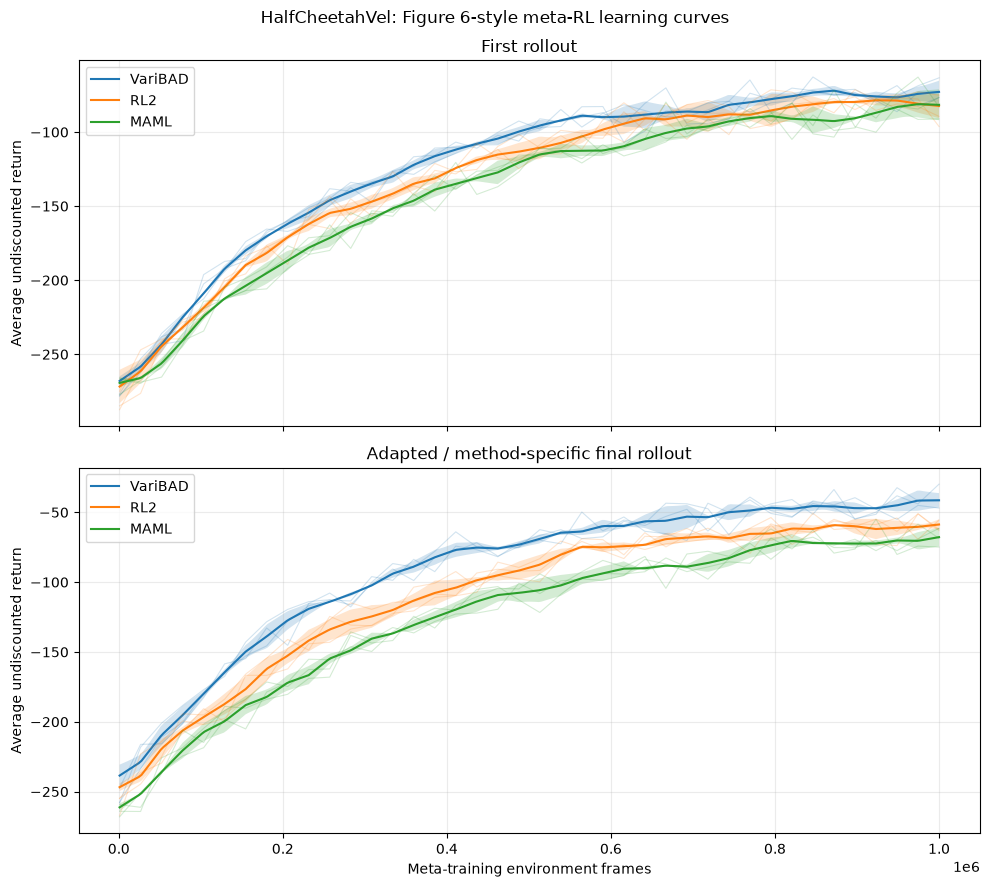

,method,seeds,final_frames_mean,first_rollout_mean,first_rollout_std,adapted_mean,adapted_std,mean_adaptation_gain
0,VariBAD,3,1000000.0,-74.743710,2.265472,-44.810046,1.819054,29.933664
1,RL2,3,1000000.0,-80.100602,4.646582,-60.660726,3.242337,19.439876
2,MAML,3,1000000.0,-84.848911,5.725916,-70.495123,1.731246,14.353788


In [270]:
def make_synthetic_plotting_demo() -> Dict[str, List[Dict[str, Any]]]:
    demo: Dict[str, List[Dict[str, Any]]] = {
        "VariBAD": [],
        "RL2": [],
        "MAML": [],
    }
    frames = np.linspace(1_000, 1_000_000, 40)

    for method_index, method in enumerate(demo):
        for seed in range(3):
            rng = np.random.default_rng(100 * method_index + seed)
            base = -280 + 210 * (1 - np.exp(-frames / (250_000 + 50_000 * method_index)))
            first = base + rng.normal(0, 7, size=len(frames))
            adapted = base + 30 - 8 * method_index + rng.normal(0, 7, size=len(frames))

            demo[method].append(
                {
                    "method": method,
                    "seed": seed,
                    "frames": frames.copy(),
                    "first_rollout_return": first,
                    "adapted_return": adapted,
                    "metadata": {"synthetic_demo": True},
                }
            )

    return demo


# Uncomment to test the plotting utilities.
synthetic_histories = make_synthetic_plotting_demo()
plot_figure6_halfcheetahvel(
    synthetic_histories,
    smoothing_window=3,
    show_individual_seeds=True,
)
display(summarize_final_performance(synthetic_histories))

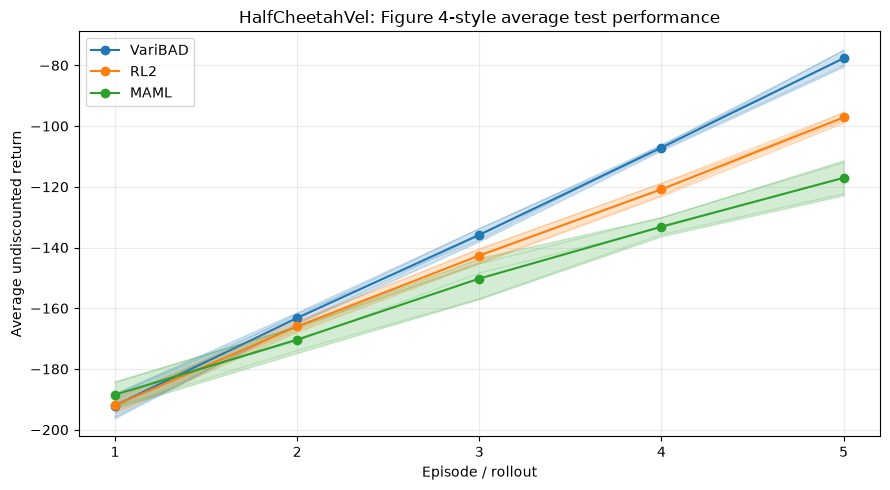

In [271]:
def make_synthetic_figure4_demo() -> Dict[str, np.ndarray]:
    """Create synthetic arrays only for testing the Figure 4 plotting utility."""
    demo: Dict[str, np.ndarray] = {}
    num_seeds = 3
    num_tasks = 8
    num_rollouts = FIGURE4_EVALUATION_ROLLOUTS

    for method_index, method in enumerate(("VariBAD", "RL2", "MAML")):
        values = np.empty((num_seeds, num_tasks, num_rollouts), dtype=np.float64)
        for seed in range(num_seeds):
            rng = np.random.default_rng(1_000 * method_index + seed)
            adaptation = 28.0 - 5.0 * method_index
            for task in range(num_tasks):
                start = -190.0 + rng.normal(0.0, 8.0)
                trend = adaptation * np.arange(num_rollouts)
                values[seed, task] = start + trend + rng.normal(0.0, 5.0, num_rollouts)
        demo[method] = values

    return demo


# Uncomment to test the Figure 4 plotting utility.
synthetic_figure4_results = make_synthetic_figure4_demo()
plot_figure4_halfcheetahvel(
    synthetic_figure4_results,
    show_individual_seeds=True,
)


# Part VII - Final evaluation and figures


### Figure 4 final-checkpoint evaluation

After selecting checkpoints without using the test tasks, run a separate five-rollout evaluation for
Figure 4. The rollout sequence must be continuous with respect to method-specific adaptation state,
even though the physical environment resets at each episode boundary. Use the exact same selected
checkpoint for every rollout of a task.


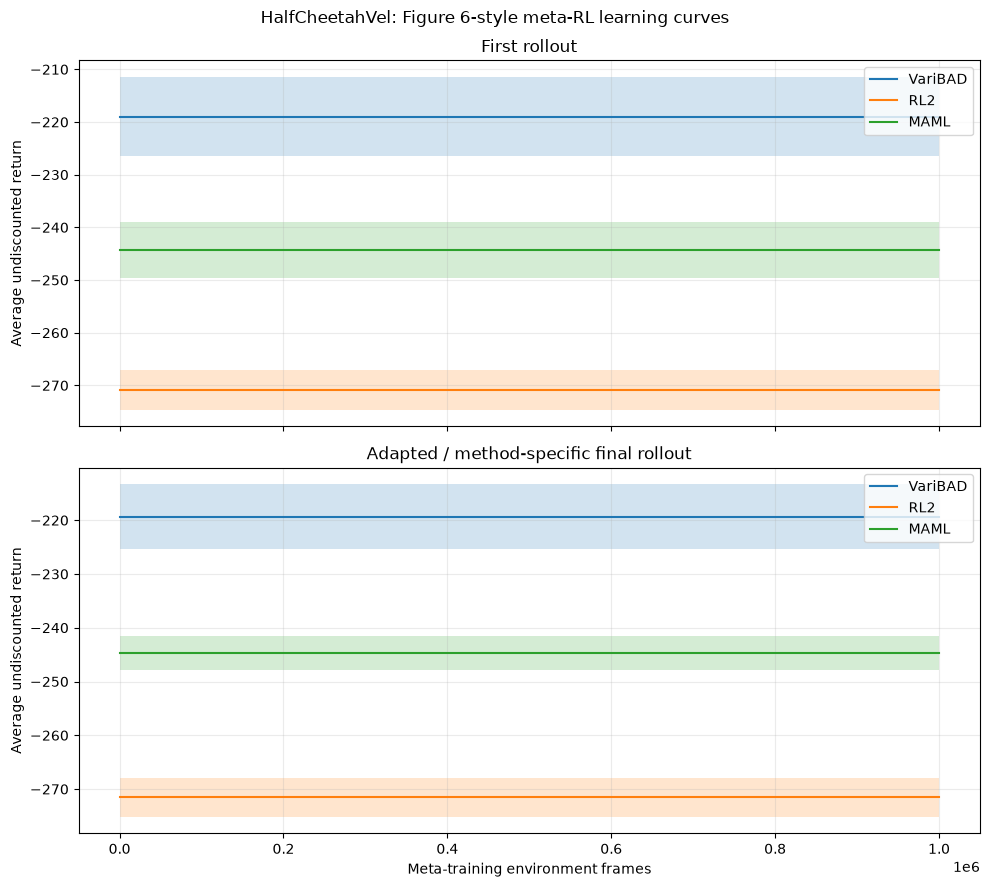

,method,seeds,final_frames_mean,first_rollout_mean,first_rollout_std,adapted_mean,adapted_std,mean_adaptation_gain
0,VariBAD,5,1000000.0,-218.996144,8.606830,-219.368498,6.928310,-0.372354
2,MAML,5,1000000.0,-244.289827,6.038935,-244.680132,3.599068,-0.390305
1,RL2,5,1000000.0,-270.849606,4.290161,-271.555074,4.123240,-0.705468


In [272]:
if any(all_histories.values()):
    plot_figure6_halfcheetahvel(
        all_histories,
        smoothing_window=3,
        show_individual_seeds=len(CONFIG.seeds) < 5,
    )
    final_summary = summarize_final_performance(all_histories, tail_points=5)
    display(final_summary)
else:
    print("Run the training cell first; no learned histories are available yet.")

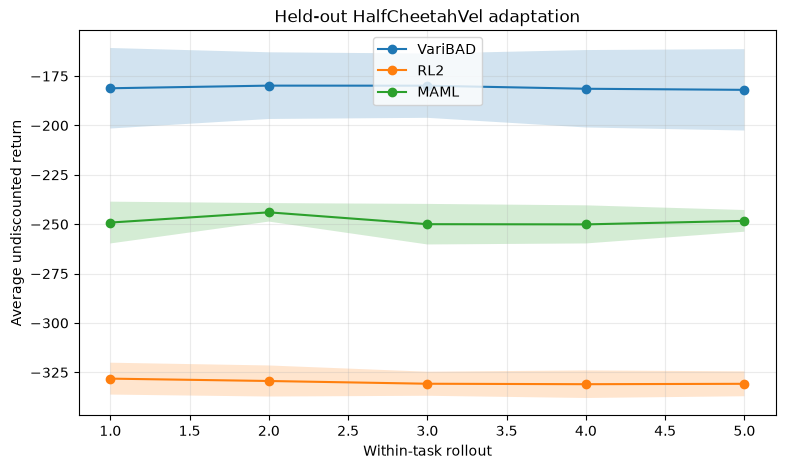

In [273]:
def collect_final_rollout_results(
    histories: Mapping[str, Sequence[Mapping[str, Any]]],
    config: ExperimentConfig,
    task_splits: TaskSplits,
    num_rollouts: int = FIGURE4_EVALUATION_ROLLOUTS,
) -> Dict[str, np.ndarray]:
    """Evaluate the final in-memory checkpoints on held-out test tasks.

    RL2 retains its GRU state and VariBAD retains its posterior across physical
    resets. MAML rollout 1 is unadapted; after every rollout, one support-gradient
    update is applied and its fast parameters are retained for the next rollout.
    The meta-initialization is restored when moving to a different task.
    """
    results: Dict[str, np.ndarray] = {}
    for method, runs in histories.items():
        if not runs:
            continue
        seed_results = []
        for run in runs:
            if "_agent" not in run:
                raise KeyError(f"{method} history does not contain its trained _agent.")
            agent = run["_agent"]
            task_results = []
            for task_index, velocity in enumerate(task_splits.test):
                reset_seed = int(run["seed"]) * 100_000 + task_index * 100
                if method == "MAML":
                    env = HalfCheetahVel(
                        float(velocity), config.env_id, config.episode_horizon
                    )
                    # Seed once; subsequent reset() calls continue the deterministic RNG stream.
                    env.reset(seed=reset_seed)
                    returns = agent.evaluate_rollouts(env, num_rollouts)
                    env.close()
                else:
                    returns = agent.evaluate_rollouts(
                        float(velocity), config, num_rollouts, reset_seed=reset_seed
                    )
                task_results.append(returns)
            seed_results.append(np.stack(task_results))
        results[method] = np.stack(seed_results)

    validate_figure4_results(results, num_rollouts)
    return results


if any(all_histories.values()):
    rollout_results = collect_final_rollout_results(
        all_histories,
        CONFIG,
        TASKS,
        FIGURE4_EVALUATION_ROLLOUTS,
    )
    plot_rollout_adaptation(rollout_results)
else:
    rollout_results: Dict[str, np.ndarray] = {}
    print("Run training before collecting final held-out rollout results.")

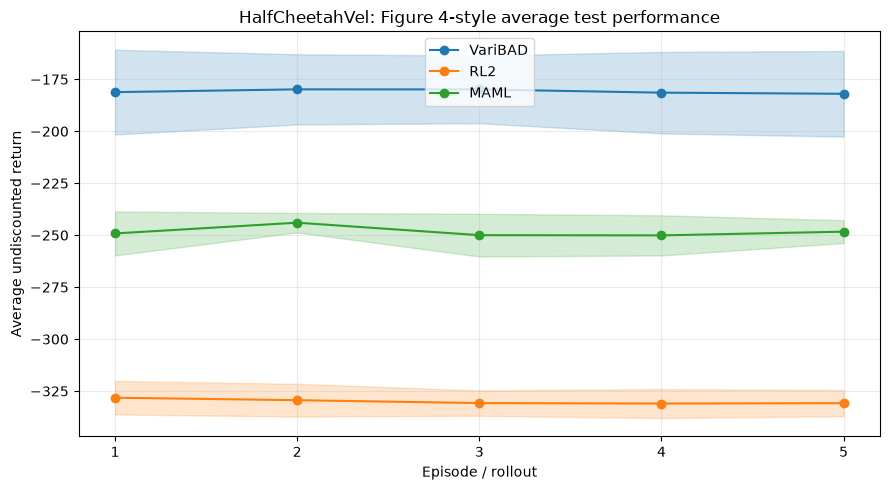

In [274]:
if rollout_results:
    validate_figure4_results(rollout_results)
    plot_figure4_halfcheetahvel(
        rollout_results,
        show_individual_seeds=len(CONFIG.seeds) < 5,
    )
else:
    print("No Figure 4 results yet; run training and the final evaluation cell first.")